---
title: "Chapter 5: More Preprocessing: Categorical Features and Text"
---

::: {.callout-lo}
By the end of this chapter, you will be able to:

- Diagnose inconsistent preprocessing and leakage, including within cross-validation.
- Explain how unknown-category handling and rare-category grouping change a representation.
- Choose an approach to high-cardinality features based on their meaning and available evidence.
- Explain what row normalization preserves and removes from word-count features.
- Construct and inspect bag-of-words features with `CountVectorizer` inside a pipeline.
- Explain how vocabulary settings, n-grams, and sparse storage affect text representations.
:::

Chapter 4 built a complete pipeline for numeric, nominal, ordinal, and binary features. Before extending that workflow, we will examine three mistakes that can survive even when the code runs. We then consider unseen and rare categories and build a representation for text. An optional expandable discussion compares feature-scaling choices. Throughout the chapter, ask two questions: **which rows may this step learn from, and which distinctions does its output preserve?**

**Imports**

In [30]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, Normalizer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

sys.path.append(str(Path("code").resolve()))
from plotting_functions import plot_improper_processing, plot_proper_processing


## Common preprocessing mistakes

Recall that a transformer's `fit` learns something from data: a scaler learns means and scales, an imputer learns replacement values, and an encoder learns categories. `transform` applies what was learned. The Golden Rule applies to each of these `fit` calls, not just the predictive model.

### Mistake 1: fitting training and test data separately

Suppose we have already split the data. What is wrong with this workflow?

```python
# Incorrect: two independently learned transformations.
train_scaler = StandardScaler()
train_scaled = train_scaler.fit_transform(X_train)

test_scaler = StandardScaler()
test_scaled = test_scaler.fit_transform(X_test)
```

Each fit learns a different coordinate system. A zero in the training representation means the training mean; a zero in the test representation means the test mean. Those need not describe the same original value.

To make the problem concrete, suppose age is our only feature:

| Fit the scaler on… | Ages | Mean | Standard deviation |
|---|---|---:|---:|
| Training set | 20, 40 | 30 | 10 |
| Test set | 40, 60 | 50 | 10 |

These are the population standard deviations used by `StandardScaler`. The same 40-year-old receives two different coordinates: $(40-30)/10=+1$ using the training scaler, but $(40-50)/10=-1$ using the separate test scaler.

In [31]:
X_age_train = pd.DataFrame({"age": [20, 40]})
y_age_train = ["class A", "class B"]
X_age_test = pd.DataFrame({"age": [40, 60]})

age_scaler = StandardScaler()
age_train_scaled = age_scaler.fit_transform(X_age_train)
age_test_correct = age_scaler.transform(X_age_test)
age_test_separate = StandardScaler().fit_transform(X_age_test)

pd.DataFrame({
    "age": X_age_test["age"],
    "training scaler": age_test_correct.ravel(),
    "separate test scaler": age_test_separate.ravel(),
})

,age,training scaler,separate test scaler
0,40,1.0,-1.0
1,60,3.0,1.0


::: {.callout-reflection title="Predict before running"}
The training ages 20 and 40 have scaled coordinates −1 and +1, respectively. Which training respondent is the nearest neighbour of the test 40-year-old under each transformation? What label will 1-NN predict?
:::

<details>
<summary>Explanation</summary>

With the training scaler, the test 40-year-old lands on the training 40-year-old and receives class B. With the separate test scaler, that same test respondent lands on the training 20-year-old and receives class A. The problem is that the training and test coordinates describe age differently.

</details>

In [32]:
age_knn = KNeighborsClassifier(n_neighbors=1).fit(age_train_scaled, y_age_train)
pd.DataFrame({
    "age": X_age_test["age"],
    "prediction with training scaler": age_knn.predict(age_test_correct),
    "prediction with separate test scaler": age_knn.predict(age_test_separate),
})

,age,prediction with training scaler,prediction with separate test scaler
0,40,class B,class A
1,60,class B,class B


Reuse the fitted training scaler for every new row. This keeps the representation consistent and avoids learning means and scales from the test set. The same reasoning applies to separately fitted encoders: a column position must keep the same meaning when the model receives new data.

### Mistake 2: fitting training and test data together

Using one scaler seems to solve the coordinate problem. Is this workflow valid?

```python
# Incorrect: test rows influence the learned representation.
X_all = np.vstack([X_train, X_test])
scaler = StandardScaler().fit(X_all)
train_scaled = scaler.transform(X_train)
test_scaled = scaler.transform(X_test)
```

The coordinate system is now shared, but the test rows helped determine it. We have used information from the data reserved for final evaluation. Fit only on the training rows, then transform both sets with that fitted object.

::: {.callout-reflection title="Does leakage require labels?"}
A student argues that the combined fit is harmless because the scaler never sees `y_test`. Do you agree?
:::

<details>
<summary>Explanation</summary>

No. Features alone can leak information: the test distribution has influenced the means and scales used to train the model. Leakage does not require test labels, and it need not improve the score in every particular dataset to make the evaluation workflow invalid.

</details>

### Mistake 3: fitting before cross-validation

Now suppose the test set is untouched. Is this evaluation valid?

```python
# Incorrect: preprocessing happens before the folds are separated.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
cross_val_score(KNeighborsClassifier(), X_train_scaled, y_train)
```

Each future validation fold has already influenced the scaler. Cross-validation is meant to evaluate the whole learning procedure on rows it has not learned from. That includes learning preprocessing parameters.

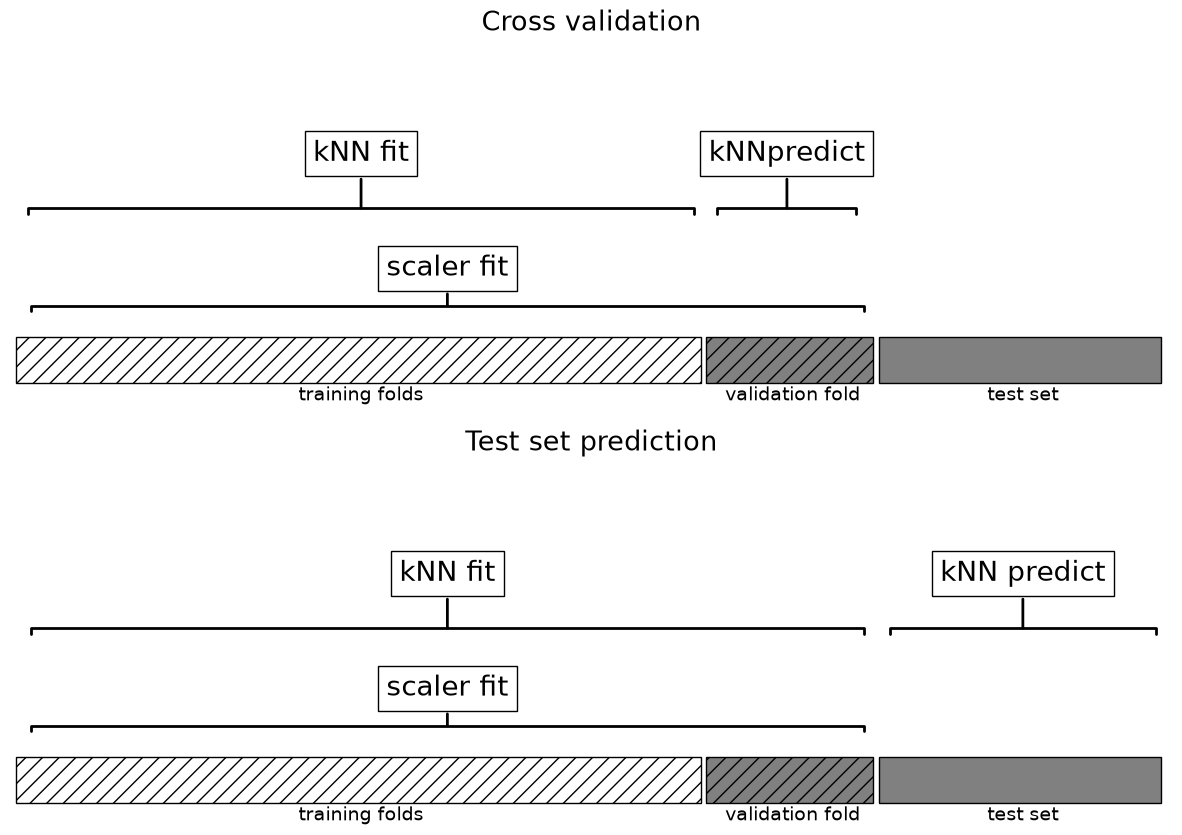

In [33]:
plot_improper_processing("kNN")
plt.show()

In the upper panel, the scaler fit includes both the training folds and the validation fold, even though the $k$-NN fit excludes the validation fold. This is where leakage occurs. The test set stays separate, but that does not repair the cross-validation estimate.

The correct workflow below restricts **both the scaler fit and the classifier fit to the training folds**. Validation rows receive only `transform`, followed by the classifier's prediction. Each upper panel shows one cross-validation split; this boundary must hold in every split. The lower panels show the final fit on all training rows before predicting on the reserved test set.

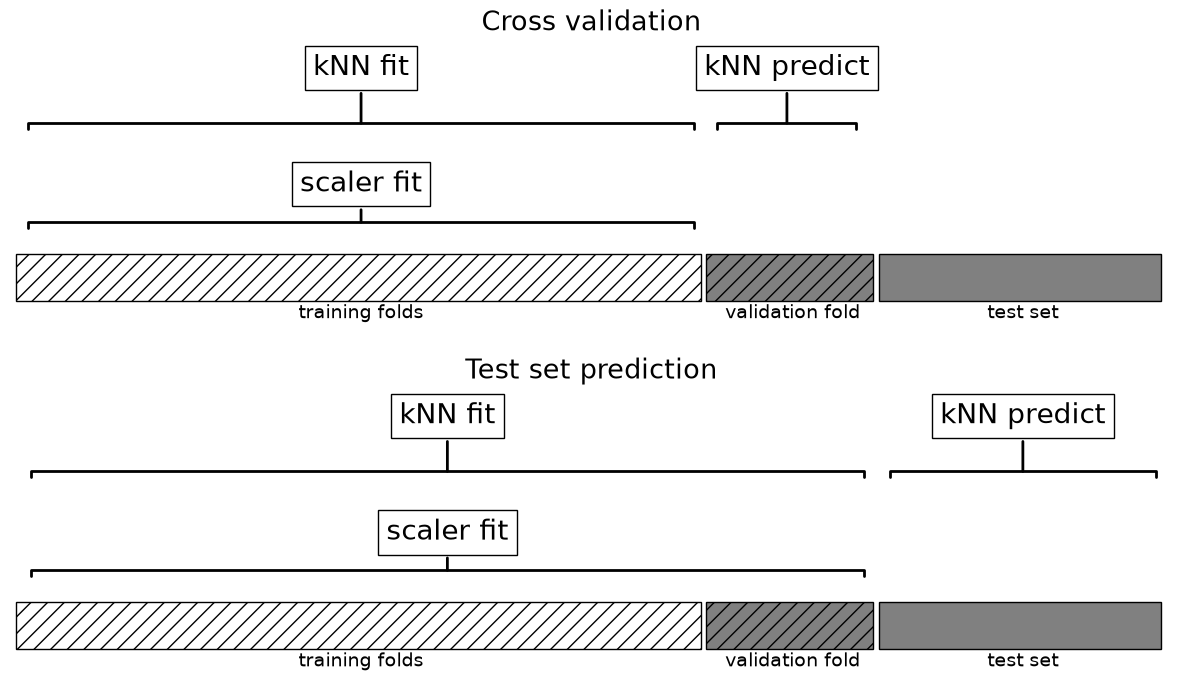

In [34]:
plot_proper_processing("kNN")
plt.show()

The repair is to pass raw features and the complete pipeline to cross-validation:

```python
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
cross_val_score(pipe, X_train, y_train)
```

Cross-validation fits a fresh copy of the pipeline in each fold. After model selection, fit the chosen pipeline on all training rows and evaluate once on the reserved test set. We will apply this workflow to text later in the chapter.

### Check feature meaning as well as fit boundaries

A pipeline coordinates the steps we specify, but it cannot decide whether those steps make sense.

| Mistake | Why it matters | Better workflow |
|---|---|---|
| Give nominal categories arbitrary integer codes | A distance-based model interprets an invented ordering and spacing | Use one-hot encoding unless an order is meaningful |
| Scale numeric identifiers as if they were measurements | Numerical proximity between IDs usually has no useful meaning | Investigate the feature's role and usually omit a pure identifier |
| Include the target or information recorded after the outcome (e.g., the actual sale price per square foot when predicting a home's sale price) | Sale price per square foot is calculated from the target: sale price/floor area. It would reveal the answer when combined with floor area | Exclude features derived from the target and retain only information available when making the prediction |

Preprocessing choices depend on the **feature, the prediction task, and the model**. For example, education level has a meaningful order. When predicting income, we might try ordinal encoding to represent increasing levels of education. When predicting a person’s preferred news source, we might use one-hot encoding so the model can treat each education level as a separate category. These are choices to evaluate, not rules about either task: ordinal codes impose a particular ordering and, for distance-based models, numeric gaps between levels; one-hot encoding does not explicitly represent that order.

The model also matters. For $k$-NN and RBF SVMs, scaling changes distances and can strongly affect predictions. Decision trees split one feature at a time using thresholds, so they generally do not need scaling. Feature meaning still matters: assigning arbitrary integer codes to neighbourhoods imposes an order even for a tree, whose thresholds can only separate contiguous groups of those codes at each split. Choose a representation that preserves distinctions useful for the task, and evaluate preprocessing and the estimator together as a complete pipeline.

:::: {.callout-note collapse="true" title="Optional: choosing a scale for numeric features"}

Chapter 4 introduced `StandardScaler` because features measured in different units can contribute very differently to distances. Standardization is one choice; another is to map each feature's training range to a common interval.

| Transformer | What it learns for each feature | Result on the training data |
|---|---|---|
| `StandardScaler` | Mean and standard deviation | Mean 0 and standard deviation 1 for nonconstant features |
| `MinMaxScaler` | Minimum and maximum | Minimum 0 and maximum 1 with the default range |
| `RobustScaler` | Median and interquartile range (by default) | Median 0 and interquartile range 1 for features with a nonzero interquartile range |

For a feature with distinct training minimum and maximum, min–max scaling computes $(x-x_{\min})/(x_{\max}-x_{\min})$. All three transformers act **column by column** and reuse the learned quantities for new rows. First, compare standardization and min–max scaling on a few training ages:

In [35]:
scaling_ages = pd.DataFrame({"age": [20, 30, 40]})
standard_age_scaler = StandardScaler().fit(scaling_ages)
minmax_age_scaler = MinMaxScaler().fit(scaling_ages)
pd.DataFrame({
    "age": scaling_ages["age"],
    "standardized": standard_age_scaler.transform(scaling_ages).ravel(),
    "min–max scaled": minmax_age_scaler.transform(scaling_ages).ravel(),
})

,age,standardized,min–max scaled
0,20,-1.224745,0.0
1,30,0.000000,0.5
2,40,1.224745,1.0


Neither standardization nor min–max scaling changes the ordering of values within a feature. They use different definitions of scale, so they can change how much one feature contributes to a distance relative to another. Neither is a remedy for outliers: extreme training values can affect both, and a very wide training range can compress most min–max-scaled values into a small interval.

Suppose most homes in our training data have floor areas between 800 and 2,000 square feet, but one mansion has an area of 20,000 square feet. That mansion stretches the range used by `MinMaxScaler` and affects the mean and standard deviation used by `StandardScaler`. We might prefer a scale that describes the typical homes without being pulled so strongly by one extreme value.

`RobustScaler` does this by focusing on the middle of the data. By default, it subtracts the **median**, the middle value, and divides by the spread of the **middle half of the values**. That spread is called the **interquartile range (IQR)**. For example, if the middle half of the floor areas runs from 1,000 to 1,600 square feet, the IQR is 600 square feet. With a median of 1,300, a home of 1,900 square feet becomes $(1900-1300)/600=1$: it is one such spread above the median.

The mansion has less influence on this choice of center and scale, but it is still in the data and still receives a large transformed value. Robust scaling does **not** remove or clip outliers, so extreme observations can still affect distances after scaling.

::: {.callout-reflection title="Predict before running"}
The training ages range from 20 to 40. With the fitted `MinMaxScaler`, where will a new age of 50 land? Must every transformed value lie between 0 and 1?
:::

<details>
<summary>Explanation</summary>

It maps to $(50-20)/(40-20)=1.5$. The default range describes the training minimum and maximum, not a bound on future values. Do not refit the scaler on new rows to force them into the interval.

</details>

Use standardization as a reasonable starting point for the distance-based models we have studied. Min–max scaling is an alternative when expressing values relative to the observed training range suits the application. Consider robust scaling when you want the fitted center and scale to be less sensitive to extreme observations. If choosing among scalers based on performance, compare complete pipelines using training-data cross-validation. A different operation, **row normalization**, will make more sense once we have introduced word-count features.

::::


## Dealing with unknown categories

An encoder learns categories from its training data. A rare category may occur only in a validation fold, and a new category can also appear after deployment. The default `OneHotEncoder` raises an error when asked to transform a category it has not seen. We can reproduce that situation without fitting a predictive model.

In [36]:
training_majors = pd.DataFrame({"major": ["Computer Science", "History", "History"]})
new_majors = pd.DataFrame({"major": ["Biology", "Physics", "History"]})
encoder = OneHotEncoder(sparse_output=False)
encoder.fit(training_majors)
try:
    encoder.transform(new_majors)
except ValueError as error:
    print(error)

Found unknown categories ['Physics', 'Biology'] in column 0 during transform


Setting `handle_unknown="ignore"` keeps the learned feature space fixed. An unseen major is represented by zeros in every learned `major` indicator column. This prevents an error, but it also makes all unseen majors indistinguishable from one another.

In [37]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(training_majors)
pd.DataFrame(
    encoder.transform(new_majors),
    columns=encoder.get_feature_names_out(),
    index=new_majors["major"],
)

,major_Computer Science,major_History
major,,
Biology,0.0,0.0
Physics,0.0,0.0
History,0.0,1.0


The transformation now completes, but `ignore` is a modelling choice rather than a universal fix. If unseen categories will be common or need to be distinguished, we might instead group rare categories, redesign the feature, or use an encoder that explicitly represents infrequent values.

### Categories known independently of the data

Sometimes the complete set of categories is defined independently of the observed dataset. For example, Canadian provinces and territories. Supplying such a published list does not use information from validation or test examples, so it does not violate the Golden Rule. This differs from inspecting the full dataset to discover which categories happen to occur.

### Categorical features with two possible categories

One-hot encoding a two-category feature normally creates two complementary columns. A single indicator contains the same information: knowing that one category is absent tells us that the other is present. `OneHotEncoder(drop="if_binary")` therefore emits one column for binary features while retaining all columns for features with more than two categories.

In [38]:
binary_values = pd.DataFrame({"enjoy_course": ["Yes", "No", "Yes"]})
binary_encoder = OneHotEncoder(drop="if_binary", sparse_output=False)
pd.DataFrame(
    binary_encoder.fit_transform(binary_values),
    columns=binary_encoder.get_feature_names_out(),
)

,enjoy_course_Yes
0,1.0
1,0.0
2,1.0


Dropping an indicator is optional, not a requirement for every model. It changes distances and can affect model behaviour. Also, combining a dropped category with `handle_unknown="ignore"` makes an unseen value and the dropped category share the all-zero representation. Decide whether that ambiguity is acceptable for your problem.

## High-cardinality features

One-hot encoding creates one feature per category. When a feature has many categories, some indicators may occur too rarely for the model to learn a reliable pattern. Depending on the problem, we might group categories using domain knowledge—for example, countries into regions—or combine infrequent values into an `other` category. Such grouping changes the information available to the model and should be justified rather than applied mechanically.

A feature with many distinct values is called **high cardinality**. A postal code may contain useful geographic information, whereas a unique transaction ID may offer little that generalizes to a new transaction. Replacing one-hot encoding with arbitrary integer codes saves columns but invents distances; it does not solve that modelling problem. Sparse storage can reduce memory use, but it cannot make rare categories more informative. Any frequency-based grouping must be learned from the training portion of each fold.


### A worked example: grouping infrequent neighbourhoods

Suppose a housing dataset contains many neighbourhood names. A few occur often, while many have only a handful of observations. This **long tail** of rare categories is common in high-cardinality features. We will illustrate it with 12 neighbourhoods—still a modest number compared with some real datasets—and inspect what grouping preserves and loses.

In [39]:
neighbourhood_counts = {
    "Downtown": 40,
    "Kitsilano": 25,
    "Mount Pleasant": 15,
    "Marpole": 4,
    "Renfrew": 4,
    "Kerrisdale": 3,
    "Fairview": 3,
    "Sunset": 2,
    "Hastings-Sunrise": 2,
    "Dunbar": 1,
    "Strathcona": 1,
    "Shaughnessy": 1,
}
training_neighbourhoods = pd.DataFrame({
    "neighbourhood": [
        name for name, count in neighbourhood_counts.items() for _ in range(count)
    ]
})
training_neighbourhoods["neighbourhood"].value_counts()

neighbourhood
Downtown            40
Kitsilano           25
Mount Pleasant      15
Marpole              4
Renfrew              4
Kerrisdale           3
Fairview             3
Sunset               2
Hastings-Sunrise     2
Dunbar               1
Strathcona           1
Shaughnessy          1
Name: count, dtype: int64

In [40]:
full_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
full_encoder.fit(training_neighbourhoods)

rare_encoder = OneHotEncoder(
    min_frequency=5,
    handle_unknown="infrequent_if_exist",
    sparse_output=False,
)
rare_encoder.fit(training_neighbourhoods)
print("Ordinary one-hot columns:", len(full_encoder.get_feature_names_out()))
print("Columns after grouping:", len(rare_encoder.get_feature_names_out()))

Ordinary one-hot columns: 12
Columns after grouping: 4


Here `min_frequency=5` keeps categories occurring at least five times in the training data as separate columns. Downtown, Kitsilano, and Mount Pleasant retain their own indicators; the other nine neighbourhoods share an infrequent-category column. We reduce **12 columns to 4**, but a downstream model can no longer distinguish those nine rare neighbourhoods using this feature.

Instead of printing every training row, inspect four cases: a common training category, two different rare training categories, and a neighbourhood absent from training.

In [41]:
new_neighbourhoods = pd.DataFrame({
    "neighbourhood": ["Downtown", "Dunbar", "Marpole", "West End"]
})
pd.DataFrame(
    rare_encoder.transform(new_neighbourhoods),
    columns=rare_encoder.get_feature_names_out(),
    index=new_neighbourhoods["neighbourhood"],
)

,neighbourhood_Downtown,neighbourhood_Kitsilano,neighbourhood_Mount Pleasant,neighbourhood_infrequent_sklearn
neighbourhood,,,,
Downtown,1.0,0.0,0.0,0.0
Dunbar,0.0,0.0,0.0,1.0
Marpole,0.0,0.0,0.0,1.0
West End,0.0,0.0,0.0,1.0


`handle_unknown="infrequent_if_exist"` sends West End to the learned infrequent group. The name matters: **if fitting did not create an infrequent group**, an unknown category instead receives all zeros, as with `handle_unknown="ignore"`. Grouping does not give the model specific knowledge about West End.

The encoder also offers `max_categories` to cap the number of output columns per input feature, including the infrequent group. Both settings change which distinctions survive. Learn the groups inside the pipeline so that validation frequencies cannot influence them.

::: {.callout-reflection title="What information did we give up?"}
Suppose Dunbar and Marpole have very different typical housing prices. Can the grouped neighbourhood feature express that difference? Would reducing the number of columns alone justify grouping them?
:::

<details>
<summary>Explanation</summary>

No. Both neighbourhoods now have the same representation. Grouping may help when individual categories have little evidence, but it can also hide useful differences. Compare plausible grouping choices using cross-validation, with the encoder fitted inside each fold.

</details>

In practice, retain individual categories when enough evidence supports them; consider pooling rare values when a shared effect is plausible; and omit or redesign a feature when its values mainly identify individual records. Domain-based grouping, such as using a broader geographic region, is another option when that grouping suits the prediction problem. Sparse storage addresses memory use, while grouping changes the information available to learn from.

### Deciding whether a feature belongs in the model

A feature being available does not mean it belongs in a model. Sensitive attributes such as race or gender, and variables that act as proxies for them, require careful consideration of the application, applicable rules, measurement quality, fairness goals, and consequences of errors. Simply dropping a sensitive column does not guarantee that the model will be fair, because other features may retain closely related information.

### Preprocessing the target

In classification, `scikit-learn` estimators can usually accept string class labels directly, so one-hot encoding the target is unnecessary. Regression targets are sometimes transformed—for example, to reduce strong skew—but that transformation must be inverted when predictions are interpreted. Later chapters revisit target transformations where they are useful.

## Encoding text data

Text cannot enter the estimators we have used so far in its raw string form. We need a transformer that learns a vocabulary from the training documents and represents each document numerically. As with every learned preprocessing step, vocabulary construction must happen inside the training workflow.

### From messages to bag-of-words features

Consider a small spam-classification dataset in which `sms` contains the message and `target` records whether it is spam. The message is neither a numeric measurement nor one value from a fixed categorical vocabulary.

In [42]:
toy_spam = [
    [
        "URGENT!! URGENT!! As a valued network customer you have been selected to receive a £900 prize reward!",
        "spam",
    ],
    ["Lol you are always so convincing.", "non spam"],
    ["Nah I don't think he goes to usf, he lives around here though", "non spam"],
    [
        "URGENT! You have won a 1 week FREE membership in our £100000 prize Jackpot!",
        "spam",
    ],
    [
        "Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030",
        "spam",
    ],
    ["Congrats! I can't wait to see you!!", "non spam"],
]
toy_df = pd.DataFrame(toy_spam, columns=["sms", "target"])
toy_df

,sms,target
0,URGENT!! URGENT!! As a valued network customer...,spam
1,Lol you are always so convincing.,non spam
2,"Nah I don't think he goes to usf, he lives aro...",non spam
3,URGENT! You have won a 1 week FREE membership ...,spam
4,Had your mobile 11 months or more? U R entitle...,spam
5,Congrats! I can't wait to see you!!,non spam


A natural first thought is to treat each message as a categorical value and one-hot encode it. The following deliberately inappropriate example shows why that representation does not generalize.

In [43]:
### DO NOT DO THIS.
enc = OneHotEncoder(sparse_output=False)
transformed = enc.fit_transform(toy_df[["sms"]])
pd.DataFrame(transformed, columns=enc.categories_)

,Congrats! I can't wait to see you!!,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030,Lol you are always so convincing.,"Nah I don't think he goes to usf, he lives around here though",URGENT! You have won a 1 week FREE membership in our £100000 prize Jackpot!,URGENT!! URGENT!! As a valued network customer you have been selected to receive a £900 prize reward!
0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0
5,1.0,0.0,0.0,0.0,0.0,0.0


One-hot encoding complete messages treats each distinct message as an unrelated category. Because most messages occur only once, the resulting columns provide almost no reusable information for a new message. We need features based on smaller units that recur across documents.

Representing language computationally is a central problem in natural language processing (NLP). Common representations include bag-of-words counts, TF–IDF features, and learned embeddings. We begin with bag-of-words because its features are concrete and easy to inspect.

A **bag-of-words** representation instead learns a vocabulary of tokens from the training documents, then represents each document by the count—or sometimes simply the presence—of each vocabulary token. The representation discards word order and most syntax: it records which words are in the bag, not how they are arranged.

![](img/bag-of-words.png)

[Source](https://web.stanford.edu/~jurafsky/slp3/4.pdf)       

`CountVectorizer` implements this representation in `scikit-learn`. It converts a collection of documents into a document–term matrix: each row is a document, each column is a vocabulary token learned during `fit`, and each entry counts how often that token occurs in the document.

::: {.callout-note}
In the natural language processing (NLP) community, a collection of text documents is called a **corpus** (plural: corpora).
:::

### Build a small document–term matrix

Before examining all the SMS words, consider three short messages. Read each message as a document. With the default lowercasing, the vocabulary is `free`, `lunch`, `meeting`, `now`, and `prize`. Try counting each token yourself, including the repeated `prize`.

In [44]:
small_messages = ["Free prize prize", "Free lunch now", "Lunch meeting"]
small_vec = CountVectorizer()
small_counts = small_vec.fit_transform(small_messages)
pd.DataFrame(
    small_counts.toarray(),
    columns=small_vec.get_feature_names_out(),
    index=small_messages,
)

,free,lunch,meeting,now,prize
Free prize prize,1,0,0,0,2
Free lunch now,1,1,0,1,0
Lunch meeting,0,1,1,0,0


The first row records one occurrence of `free` and two of `prize`; its other entries are zero. A column has the same meaning in every row. Unlike one-hot encoding whole messages, this representation lets different messages share features.

`fit_transform` learns the vocabulary and creates counts for the training documents. `transform` keeps those columns fixed for new messages.

In [45]:
new_messages = ["Free meeting tomorrow", "Tomorrow only"]
pd.DataFrame(
    small_vec.transform(new_messages).toarray(),
    columns=small_vec.get_feature_names_out(),
    index=new_messages,
)

,free,lunch,meeting,now,prize
Free meeting tomorrow,1,0,1,0,0
Tomorrow only,0,0,0,0,0


`tomorrow` and `only` were absent during fitting and are ignored. The first message still has known tokens to count; the second becomes an all-zero row. This does not mean that it is empty or meaningless, only that none of its tokens belongs to the learned vocabulary. Refitting on these messages would change the feature space and break its agreement with a model trained on the original columns.

For the six SMS messages, the same process produces a wider matrix:

In [46]:
vec = CountVectorizer()
X_counts = vec.fit_transform(toy_df["sms"])
bow_df = pd.DataFrame(
    X_counts.toarray(), columns=vec.get_feature_names_out(), index=toy_df["sms"]
)
bow_df

,08002986030,100000,11,900,always,are,around,as,been,call,...,update,urgent,usf,valued,wait,week,with,won,you,your
sms,,,,,,,,,,,,,,,,,,,,,
URGENT!! URGENT!! As a valued network customer you have been selected to receive a £900 prize reward!,0,0,0,1,0,0,0,1,1,0,...,0,2,0,1,0,0,0,0,1,0
Lol you are always so convincing.,0,0,0,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
"Nah I don't think he goes to usf, he lives around here though",0,0,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
URGENT! You have won a 1 week FREE membership in our £100000 prize Jackpot!,0,1,0,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,1,1,0
Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030,1,0,1,0,0,0,0,0,0,1,...,2,0,0,0,0,0,1,0,0,1
Congrats! I can't wait to see you!!,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0


::: {.callout-important}
`CountVectorizer` expects a one-dimensional sequence of documents, so we pass a pandas Series rather than a one-column DataFrame. If a dataset has multiple text columns that should have separate vocabularies, each column needs its own vectorizer branch in a `ColumnTransformer`.
:::

In [47]:
X_counts

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 71 stored elements and shape (6, 61)>

Most vocabulary words do not occur in any one document, so most entries in a document–term matrix are zero. `CountVectorizer` therefore returns a **sparse matrix**, which stores only nonzero values and their locations. Sparse storage has some bookkeeping overhead, but it can save substantial memory and computation when the fraction of nonzero entries is small.

In [48]:
print("The total number of elements: ", np.prod(X_counts.shape))
print("The number of non-zero elements: ", X_counts.nnz)
print(
    "Proportion of non-zero elements: %0.4f" % (X_counts.nnz / np.prod(X_counts.shape))
)
print(
    "The value at cell 3,%d is: %d"
    % (vec.vocabulary_["jackpot"], X_counts[3, vec.vocabulary_["jackpot"]])
)

The total number of elements:  366
The number of non-zero elements:  71
Proportion of non-zero elements: 0.1940
The value at cell 3,27 is: 1


::: {.callout-reflection}
`StandardScaler` normally subtracts the mean of each feature. What would happen to a sparse matrix if centring turned most of its zeros into nonzero values?
:::

<details>
<summary>Explanation</summary>

Centring would destroy the matrix's sparsity and could require far more memory. When scaling sparse features, use a method that preserves zeros; for `StandardScaler`, this means setting `with_mean=False`. Word-count features are not routinely standardized, however, and transformations designed specifically for term counts are another option beyond this introduction.

</details>

The `.toarray()` calls above make these tiny matrices easy to display. Avoid converting a large document–term matrix to a dense array just to inspect it; inspect its shape, nonzero entries, or a small slice instead.

::: {.callout-note title="One-hot encoding can also produce sparse features"}

By default, `OneHotEncoder` returns a sparse matrix. This representation can save considerable memory when the encoded feature matrix contains many categories and therefore many zeros.

For a small number of categories, a dense array is often more convenient and the memory difference is usually unimportant. Use `sparse_output=False` to request a dense result.

:::

### Optional extension: normalizing document rows

A longer document often contains more word occurrences. Consequently, two documents with similar relative word usage can have quite different count magnitudes. If we want similarity to reflect relative word usage rather than overall count magnitude, we can **normalize each document row**.

For example, consider two messages represented using the vocabulary `free`, `prize`, and `meeting`. The rows `[1, 2, 0]` and `[2, 4, 0]` have the same proportions: the second simply doubles every count.

`Normalizer` with its default `norm="l2"` divides each nonzero row by its Euclidean length: the square root of the sum of its squared entries. The first row has length $\sqrt{1^2+2^2}=\sqrt{5}$; the second has twice that length. After division, both have the same coordinates and length 1.

In [49]:
proportional_messages = ["free prize prize", "free free prize prize prize prize"]
normalization_vec = CountVectorizer(vocabulary=["free", "prize", "meeting"])
proportional_counts = normalization_vec.fit_transform(proportional_messages)
normalized_counts = Normalizer().fit_transform(proportional_counts)
pd.DataFrame(
    normalized_counts.toarray(),
    columns=normalization_vec.get_feature_names_out(),
    index=proportional_messages,
)

,free,prize,meeting
free prize prize,0.447214,0.894427,0.0
free free prize prize prize prize,0.447214,0.894427,0.0


Unlike `StandardScaler` and `MinMaxScaler`, which learn a scale for each **column**, `Normalizer` works across the entries of each **row**. It does not learn population means, ranges, or other statistics from training rows; its `fit` method exists for API consistency. Each row is normalized independently, and an all-zero row stays all zero. Dividing the stored counts by a row's length also preserves sparse storage.

::: {.callout-reflection title="What information disappears?"}
Could a classifier distinguish the two messages using only these normalized features? If repetition were a useful spam signal, what would we lose?
:::

<details>
<summary>Explanation</summary>

No: the normalized rows are identical. Normalization removes overall count magnitude, so it loses the distinction between a message and one that repeats every token twice. It retains ratios between nonzero counts, rather than making every positive count equal to 1 as `binary=True` does.

</details>

This is an optional representation choice, not a requirement for BOW. Overall magnitude may carry useful information, and observed vocabulary counts do not capture a document's full length when some tokens are ignored. To try normalization, put it between the vectorizer and classifier:

```python
normalized_text_pipe = make_pipeline(CountVectorizer(), Normalizer(), SVC())
```

Compare that complete pipeline with the unnormalized version using training-data cross-validation. The vocabulary still has to be learned inside each fold even though the normalization itself learns no statistics across documents.

### Controlling the representation

A vectorizer's hyperparameters determine which distinctions a model can use. They are modelling choices rather than generic cleanup settings.

| Setting | Decision it controls | Possible cost |
|---|---|---|
| `binary=True` | Record presence rather than occurrence counts | Repetition is no longer distinguishable |
| `min_df` | Exclude tokens appearing in too few documents | Rare but useful signals may disappear |
| `max_df` | Exclude tokens appearing in too many documents | Common tokens can still be predictive |
| `max_features` | Keep at most this many vocabulary terms, ranked by corpus term frequency | Frequent terms are not necessarily the most predictive |
| `ngram_range` | Include adjacent token sequences as well as, or instead of, individual tokens | More features and rarer patterns |

**Counts versus presence.** The first small message contains `prize` twice. With `binary=True`, the entry becomes 1. This keeps evidence that a token occurred but removes evidence about how often it occurred.

In [50]:
binary_vec = CountVectorizer(binary=True)
pd.DataFrame(
    binary_vec.fit_transform(small_messages).toarray(),
    columns=binary_vec.get_feature_names_out(),
    index=small_messages,
)

,free,lunch,meeting,now,prize
Free prize prize,1,0,0,0,1
Free lunch now,1,1,0,1,0
Lunch meeting,0,1,1,0,0


**Document frequency versus occurrence count.** A token's *document frequency* is the number of documents containing it, regardless of repetition within a document. In the small corpus, `prize` occurs twice but appears in only one document; `free` occurs twice across two documents. Therefore `min_df=2` removes `prize` but retains `free`.

In [51]:
pd.DataFrame({
    "total occurrences": np.asarray(small_counts.sum(axis=0)).ravel(),
    "documents containing token": np.asarray((small_counts > 0).sum(axis=0)).ravel(),
}, index=small_vec.get_feature_names_out())

,total occurrences,documents containing token
free,2,2
lunch,2,2
meeting,1,1
now,1,1
prize,2,1


In [52]:
filtered_vec = CountVectorizer(min_df=2)
pd.DataFrame(
    filtered_vec.fit_transform(small_messages).toarray(),
    columns=filtered_vec.get_feature_names_out(),
    index=small_messages,
)

,free,lunch
Free prize prize,1,0
Free lunch now,1,1
Lunch meeting,0,1


An integer `min_df` or `max_df` specifies a document count; a floating-point value specifies a proportion of documents. For example, `max_df=0.8` excludes tokens occurring in more than 80% of the training documents. These thresholds use training documents only, and aggressive settings on a tiny corpus can remove every token.

`max_features` limits the vocabulary by total term frequency across the corpus, rather than by the number of documents containing a term or by its relationship with the target. On the SMS example, inspect the eight retained terms:

In [53]:
limited_vec = CountVectorizer(max_features=8)
limited_counts = limited_vec.fit_transform(toy_df["sms"])
limited_vec.get_feature_names_out()

array(['free', 'have', 'mobile', 'the', 'to', 'update', 'urgent', 'you'],
      dtype=object)

**Individual words versus short sequences.** A unigram is one token; a bigram is a sequence of two adjacent tokens. `ngram_range=(1, 2)` includes both. Compare two messages with the same words in different orders.

In [54]:
order_messages = ["dogs chase cats", "cats chase dogs"]
unigram_vec = CountVectorizer()
pd.DataFrame(
    unigram_vec.fit_transform(order_messages).toarray(),
    columns=unigram_vec.get_feature_names_out(),
    index=order_messages,
)

,cats,chase,dogs
dogs chase cats,1,1,1
cats chase dogs,1,1,1


In [55]:
ngram_vec = CountVectorizer(ngram_range=(1, 2))
pd.DataFrame(
    ngram_vec.fit_transform(order_messages).toarray(),
    columns=ngram_vec.get_feature_names_out(),
    index=order_messages,
)

,cats,cats chase,chase,chase cats,chase dogs,dogs,dogs chase
dogs chase cats,1,0,1,1,0,1,1
cats chase dogs,1,1,1,0,1,1,0


The unigram rows are identical. Bigrams distinguish `dogs chase` from `cats chase`, recovering some local order. The larger vocabulary also contains more patterns with little evidence, and bigrams do not provide general understanding of a sentence.

::: {.callout-reflection title="Which distinction survives?"}
Consider “free prize” and “free free prize”. Which settings make their feature rows identical: default counts, `binary=True`, or counts with `ngram_range=(1, 2)`? Explain without running code.
:::

<details>
<summary>Explanation</summary>

Only `binary=True` with the default unigram representation makes them identical. Default counts retain the extra `free`; unigram-plus-bigram counts also retain it and add the `free free` bigram, provided these tokens and sequences are in the fitted vocabulary.

</details>

Before counting, `CountVectorizer` lowercases text by default and keeps tokens containing at least two word characters. Most punctuation and single-character tokens are excluded. For example, `FREE` and `free` share a feature, while a single-letter `I` is omitted. These defaults suit some applications better than others. Removing common “stop words” is also optional: a word such as `not` may carry information we want to preserve. Change preprocessing choices to suit the task, not because a longer cleanup recipe appears more thorough.

### Text preprocessing inside a pipeline

The six SMS messages help us inspect features, but they are too few for a useful performance estimate. For an evaluation example, we will use the larger SMS dataset included with the book and reserve a test set before fitting anything.

In [56]:
sms_df = pd.read_csv("data/spam.csv", encoding="latin-1")
sms_df = sms_df[["v1", "v2"]].rename(columns={"v1": "target", "v2": "sms"})
X_sms_train, X_sms_test, y_sms_train, y_sms_test = train_test_split(
    sms_df["sms"], sms_df["target"], test_size=0.2,
    random_state=123, stratify=sms_df["target"],
)
sms_df["target"].value_counts()

target
ham     4825
spam     747
Name: count, dtype: int64

In [57]:
text_pipe = make_pipeline(CountVectorizer(), SVC())
text_cv_scores = cross_val_score(text_pipe, X_sms_train, y_sms_train, cv=5)
print(f"Mean validation accuracy: {text_cv_scores.mean():.3f}")
print(f"Always predict ham: {(y_sms_train == 'ham').mean():.3f}")

Mean validation accuracy: 0.977
Always predict ham: 0.866


Pass the **raw message strings** to cross-validation. In each fold, the vectorizer learns its vocabulary from that fold's training messages, and the SVM learns from those counts. Validation messages are transformed with that fitted vocabulary. Words found only in a validation message are ignored, and different folds may learn different vocabularies.

The dataset calls non-spam messages `ham`. Because ham is more common, compare accuracy with the simple baseline of always predicting ham. Accuracy alone does not tell us whether the model misses spam or incorrectly blocks legitimate messages; later material develops evaluation measures that distinguish those errors.

For this demonstration, we will keep the pipeline settings fixed. Fit it on all training messages, then inspect predictions for two new messages and evaluate once on the reserved test set.

In [58]:
text_pipe.fit(X_sms_train, y_sms_train)
example_messages = pd.Series([
    "Are we still meeting for lunch tomorrow?",
    "URGENT! Claim your free prize now!",
])
pd.DataFrame({"message": example_messages,
              "prediction": text_pipe.predict(example_messages)})

,message,prediction
0,Are we still meeting for lunch tomorrow?,ham
1,URGENT! Claim your free prize now!,spam


In [59]:
print(f"Reserved test accuracy: {text_pipe.score(X_sms_test, y_sms_test):.3f}")

Reserved test accuracy: 0.986


These two predictions illustrate the API; they are not a performance estimate. The held-out score evaluates the fixed workflow. If we want to choose vocabulary settings or classifier hyperparameters, we must make those choices using training-data cross-validation and preserve the test set for the final evaluation. Chapter 6 shows how to search over pipeline hyperparameters.

### What bag-of-words cannot tell us

The identical unigram rows for “dogs chase cats” and “cats chase dogs” show a fundamental limitation: a classifier cannot recover a distinction absent from its input representation. Unigram counts discard order and syntax. They also do not explicitly represent who did what to whom, the scope of negation, or a word's meaning in context.

Word matching also misses some relationships we might want: `prize` and `reward` are separate features even when used similarly. Conversely, one word used with different meanings shares a feature. Unseen words contribute nothing, and messages made entirely of unseen tokens collapse to the same all-zero representation.

N-grams recover some local patterns, including phrases such as `not good`, but increase vocabulary size and do not solve these broader problems. Despite its limitations, bag-of-words is easy to inspect and can provide a useful baseline for tasks such as spam filtering. More contextual representations are beyond this chapter; first establish what a simple, correctly evaluated representation can achieve.

## Exercises

### Exercise 5.1: A new category

An encoder learns the categories `red` and `blue` with `handle_unknown="ignore"`. What representation will it produce for `green` and for `yellow`? Can a downstream model distinguish those two values using this feature? How does your answer change if the encoder also drops one known category?

### Exercise 5.2: A misleading workflow

A customer table includes a unique customer ID, a province, and a comment. A student ordinally encodes all three columns and scales the result before splitting. Identify the problems and propose a representation and evaluation workflow for each feature. Which learned steps must be fitted again within each cross-validation fold?

### Exercise 5.3: Too much grouping?

A training feature contains categories A, A, A, A, B, B, C, D. An encoder uses `min_frequency=3` and `handle_unknown="infrequent_if_exist"`.

1. Which categories retain their own columns, and which share a column?
2. What happens to a new category E?
3. Suppose B is associated with a different outcome from C and D. What useful distinction has grouping removed, and how would you assess whether the grouping helps overall?
4. If a different fold contains no infrequent categories, what representation does an unseen value receive?

### Exercise 5.4: Vocabulary filtering and repetition

A training corpus contains “free free prize”, “free lunch”, and “lunch meeting”. With default tokenization and `min_df=2`, which tokens survive? What counts does the first document receive? Explain why increasing the repetitions of `prize` within that first document would not save it from the filter. How would `binary=True` change the surviving counts?

### Exercise 5.5: Review a text evaluation

A student fits `CountVectorizer` on all training messages, then cross-validates an SVM on the resulting matrix. They try several `min_df` values and choose the one with the highest test accuracy.

Identify both evaluation problems. Describe a corrected workflow, including what each fold learns, what happens to words appearing only in validation, and when the test set should be used.

## Summary

- Reuse fitted training transformations for new rows, and cross-validate the complete pipeline so that validation rows cannot influence preprocessing.
- Unknown-category handling keeps learned columns fixed, but does not give the model specific knowledge about unseen categories. Dropping an indicator can make an unknown value indistinguishable from the dropped category.
- High-cardinality features require judgment about useful information, rare values, and memory. Grouping infrequent categories pools observations but removes distinctions, and the groups must be learned within each training fold.
- Bag-of-words represents documents using vocabulary token counts. Binary counts, vocabulary filters, and n-grams change which distinctions the model can use, but do not provide a complete representation of language.
- Sparse storage saves space for mostly zero feature matrices without changing their meaning. Row normalization changes the representation by preserving relative counts while removing overall magnitude.
- Keep vocabulary learning inside the predictive pipeline, compare performance with a baseline, and reserve the test set for final evaluation.
